In [61]:
import pandas as pd

# Load CSV
data = pd.read_csv("data/Indoor Air Pollution Data.csv", low_memory=False)


In [62]:
data.head()

,NH3,NO2,CO,PM2.5,Temp,Pressure,Humidity,O3,Date,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18
0,0.60,0.16,4.01,0.00,33.53,948.26,51.98,7.37,2020-11-17|11:20:53.407872,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.62,0.15,4.13,0.39,33.5,948.18,51.53,9.06,2020-11-17|11:22:41.214724,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0.69,0.14,4.45,0.39,33.36,948.15,50.5,16.47,2020-11-17|11:24:28.546567,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0.70,0.14,4.52,0.38,32.18,948.14,53.35,9.8,2020-11-17|11:26:16.884289,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0.72,0.14,4.56,0.40,31.77,948.08,53.7,17.28,2020-11-17|11:28:19.820781,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [63]:
# Drop unnamed columns
data.drop(columns=[col for col in data.columns if "Unnamed" in col], inplace=True)

In [64]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 173468 entries, 0 to 173467
Data columns (total 9 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   NH3       173465 non-null  float64
 1   NO2       173468 non-null  object 
 2   CO        173465 non-null  float64
 3   PM2.5     173465 non-null  float64
 4   Temp      173465 non-null  object 
 5   Pressure  173465 non-null  object 
 6   Humidity  173465 non-null  object 
 7   O3        173465 non-null  object 
 8   Date      173465 non-null  object 
dtypes: float64(3), object(6)
memory usage: 11.9+ MB


In [65]:
data.describe()

,NH3,CO,PM2.5
count,173465.000000,173465.000000,173465.000000
mean,0.670185,4.339625,0.057456
std,0.177971,1.615590,0.116102
min,0.290000,0.290000,0.000000
25%,0.540000,3.610000,0.000000
50%,0.650000,4.190000,0.000000
75%,0.750000,4.860000,0.000000
max,1.630000,9.920000,0.470000


In [66]:
data.shape

(173468, 9)

In [31]:
print(data.isnull().sum())

NH3         3
NO2         0
CO          3
PM2.5       3
Temp        3
Pressure    3
Humidity    3
O3          3
Date        3
dtype: int64


In [32]:
data.dropna(inplace=True)
# Remove duplicate rows if any
data = data.drop_duplicates()

In [67]:
# Fix numeric columns with bad characters (like '12.450.73')
for col in data.columns[:-1]:  # skip 'Date' column
    data[col] = data[col].astype(str).str.replace('[^0-9.]', '', regex=True)
    data[col] = data[col].apply(lambda x: x if x.count('.') <= 1 else x.replace('.', '', x.count('.') - 1))  # keep last dot
    data[col] = pd.to_numeric(data[col], errors='coerce')

#### Timestamp Parsing
The Date column was parsed into standard datetime format, replacing pipe separators with spaces. Rows with invalid or missing timestamps were removed, and the column was set as the index for time-based analysis.

In [34]:
# Convert date
data['Date'] = pd.to_datetime(data['Date'].str.replace('|', ' ', regex=False), errors='coerce')
data.dropna(inplace=True)

In [35]:
print(data.columns)

Index(['NH3', 'NO2', 'CO', 'PM2.5', 'Temp', 'Pressure', 'Humidity', 'O3',
       'Date'],
      dtype='object')


In [36]:
data = data.set_index('Date')

## Data Visualization

### Trends of Pollutants Over Time

<Figure size 1400x700 with 0 Axes>

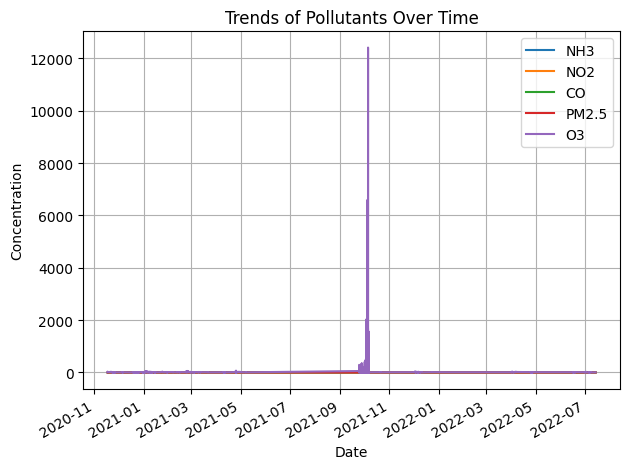

In [245]:
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 7))
data[['NH3', 'NO2', 'CO', 'PM2.5', 'O3']].plot()
plt.title('Trends of Pollutants Over Time')
plt.ylabel('Concentration')
plt.xlabel('Date')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

This line chart visualizes the trends of five key air pollutants—NH3 (Ammonia), NO2 (Nitrogen Dioxide), CO (Carbon Monoxide), PM2.5 (Particulate Matter), and O3 (Ozone)—over a recorded time period. The x-axis represents the actual dates from the dataset, while the y-axis indicates the pollutant concentration levels.

From the chart, it is evident that while most pollutant levels remain relatively low and stable, O3 shows an exceptionally high spike around late 2021. This spike significantly affects the overall scale of the graph, compressing the visible trends of the other pollutants and potentially indicating a data anomaly, measurement error, or a genuine pollution event.

This visualization is useful for identifying patterns, unusual spikes, or seasonal behaviors in pollutant levels across time. However, due to scale distortion from extreme O3 values, further analysis—such as normalization or outlier treatment—may help uncover more granular insights.


### Correlation Heatmap

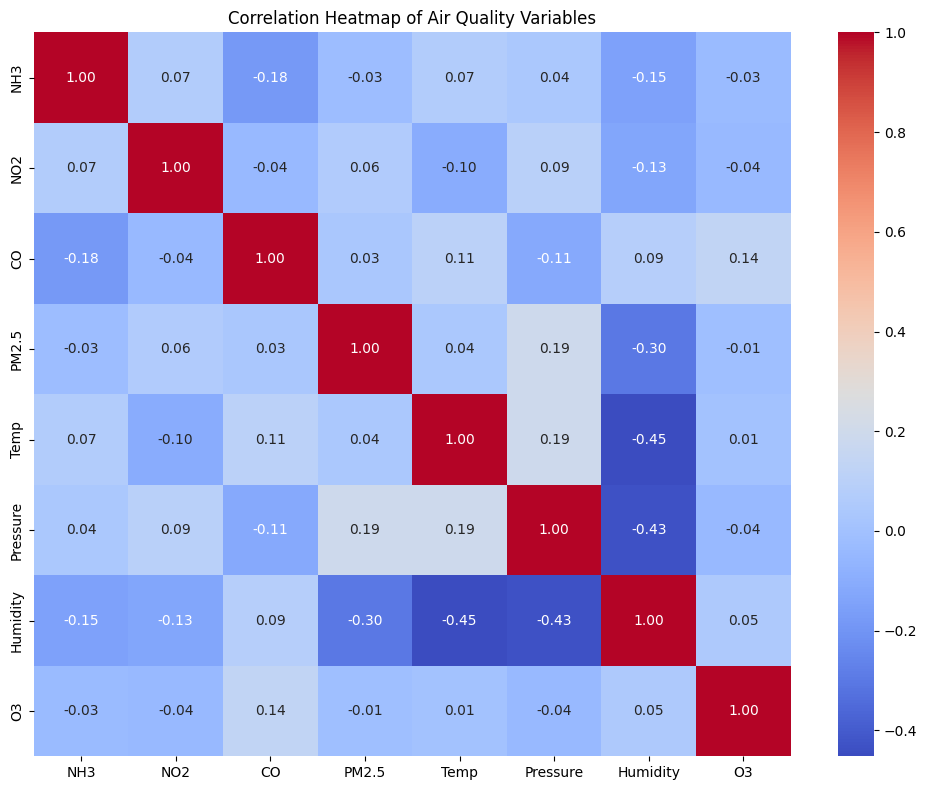

In [246]:
import seaborn as sns
# Plot 2: Correlation Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(data.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Air Quality Variables')
plt.tight_layout()
plt.show()

Key insights from the heatmap:
- **Temperature and Humidity** are strongly **negatively correlated** (-0.45), suggesting that as temperature rises, humidity tends to drop.
- **PM2.5** has a weak negative correlation with **Humidity** (-0.30), which might suggest that drier air could lead to higher particulate matter levels.
- Most pollutants have weak correlations with each other, indicating they may vary independently and originate from different sources or processes.


### Distribution Plots of Pollutants

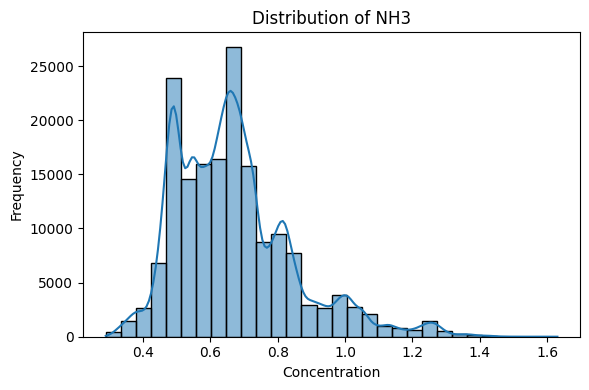

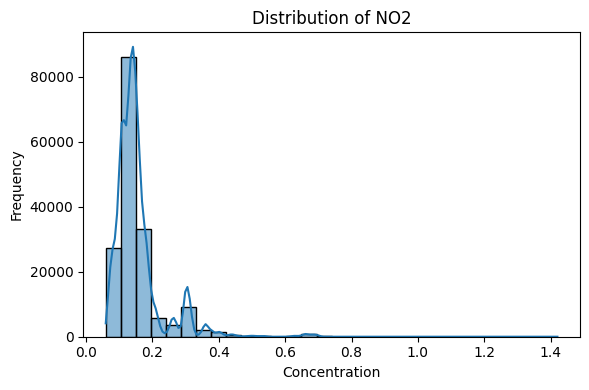

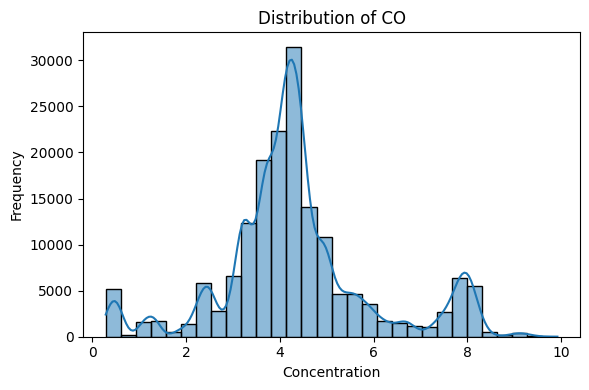

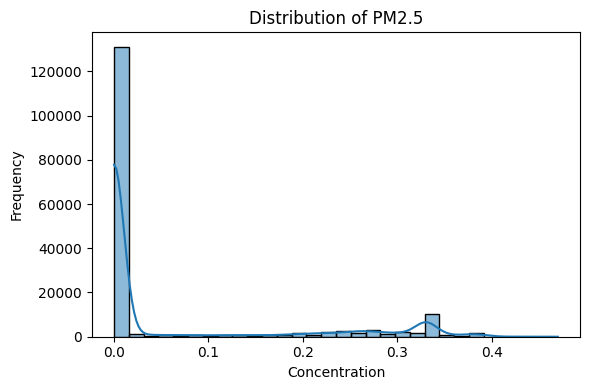

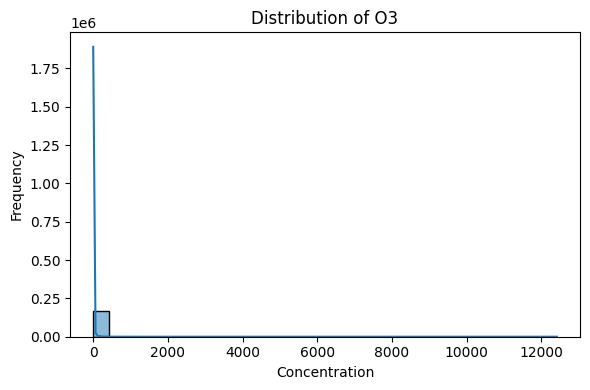

In [247]:
# Plot 3: Distribution plots of pollutants
pollutants = ['NH3', 'NO2', 'CO', 'PM2.5', 'O3']
for pollutant in pollutants:
    plt.figure(figsize=(6, 4))
    sns.histplot(data[pollutant], kde=True, bins=30)
    plt.title(f'Distribution of {pollutant}')
    plt.xlabel('Concentration')
    plt.ylabel('Frequency')
    plt.tight_layout()
    plt.show()

###  Distribution of NH₃ (Ammonia)
The histogram for NH₃ shows a moderately right-skewed distribution, with the majority of concentration values falling between 0.5 and 0.8 ppm. Multiple peaks (modes) suggest varying environmental conditions or sensor responses. The long tail toward higher concentrations indicates occasional spikes in NH₃ levels, possibly due to nearby emissions or localized sources.

### Distribution of NO₂ (Nitrogen Dioxide)
NO₂ displays a highly right-skewed distribution, with most values clustered between 0.1 and 0.2 ppm. This indicates generally low ambient levels of NO₂, but the long tail implies occasional pollution spikes. Such a pattern is common in urban air where vehicle emissions can cause transient NO₂ surges.

### Distribution of CO (Carbon Monoxide)
The CO distribution is nearly symmetric, centered around 4 to 5 ppm, indicating a consistent ambient level across time. This bell-shaped curve suggests stable indoor or ambient sources, with fewer extreme fluctuations compared to other pollutants. Occasional higher values may still reflect localized or time-specific sources (e.g., cooking or traffic).

### Distribution of PM2.5 (Particulate Matter)
PM2.5 is heavily right-skewed with a dominant spike near zero, showing that most values are extremely low. This suggests clean air conditions most of the time, with a few events contributing to measurable particulate matter. Such zero-inflated distributions are common in IAQ datasets when pollutant levels frequently fall below detection thresholds.

### Distribution of O₃ (Ozone)
The histogram for O₃ shows an extremely skewed distribution, with a large number of values near zero and a few massive spikes, pushing the frequency scale to nearly 2 million. These outliers dominate the plot, masking all normal variability. This pattern strongly suggests data anomalies or sensor errors, which should be treated (e.g., clipped, removed) before statistical modeling.



### Pairplot of Pollutants

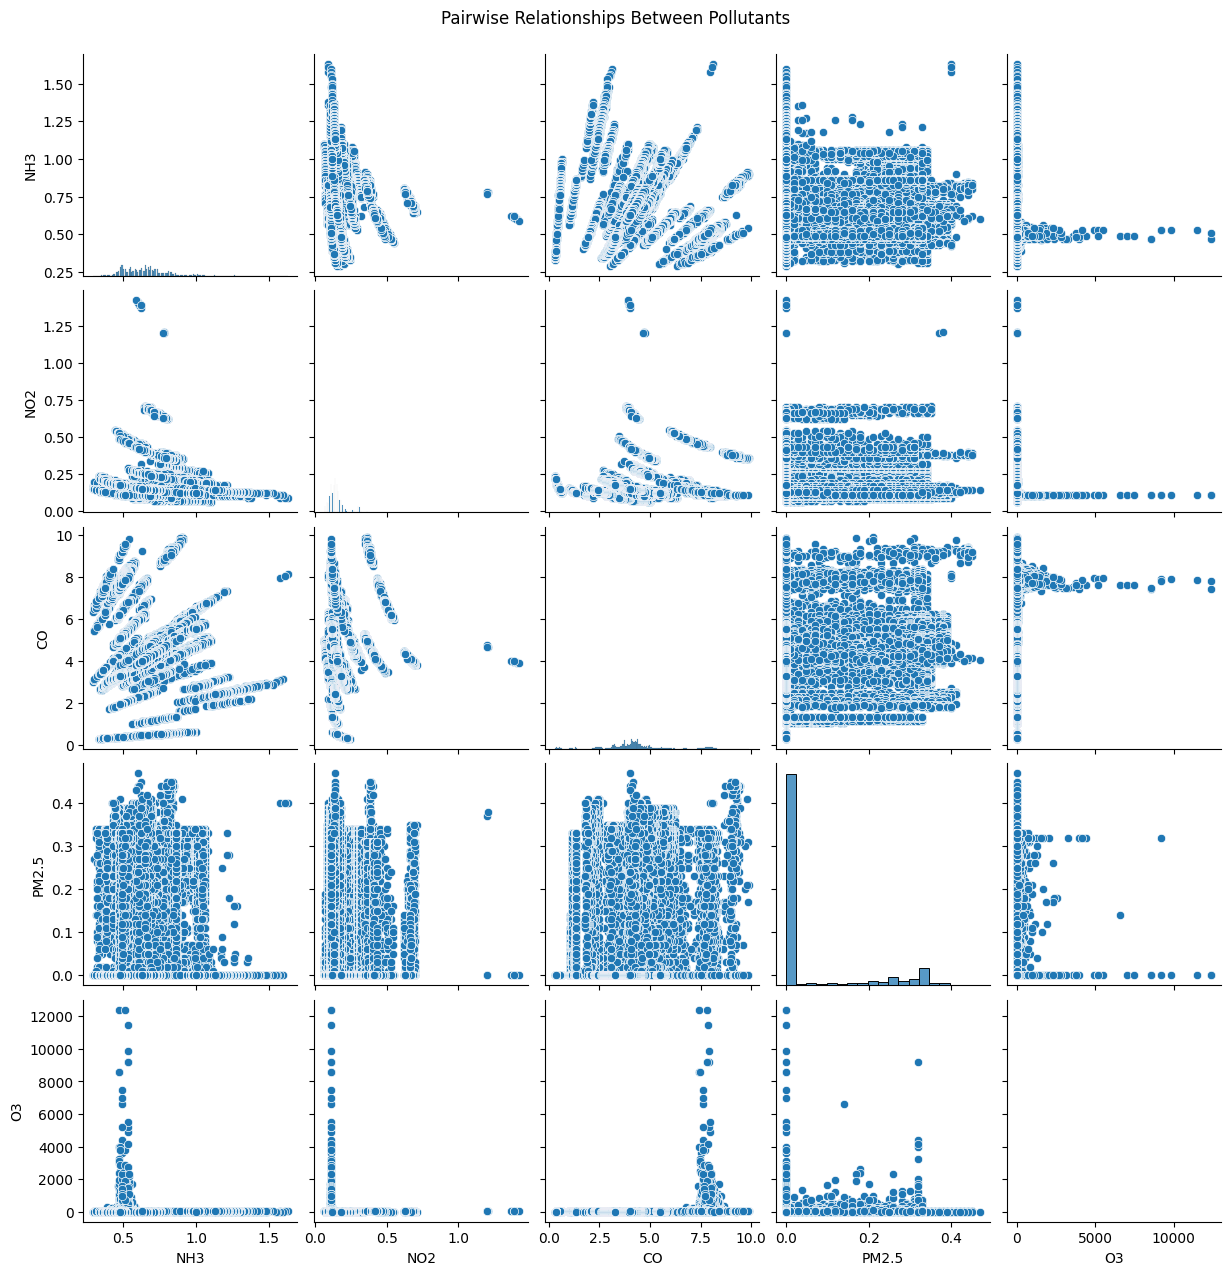

In [248]:
# Plot 4: Pairplot
sns.pairplot(data[pollutants])
plt.suptitle('Pairwise Relationships Between Pollutants', y=1.02)
plt.show()

Key observations:
- **NH3, NO2, and CO** exhibit clusters and some spread, indicating weak but varying relationships.
- **PM2.5** is tightly compressed near zero in most plots, reflecting its skewed distribution.
- **O3** values are heavily skewed with extreme outliers, dominating many scatter plots and reducing clarity.


### Boxplot of Air Pollutants

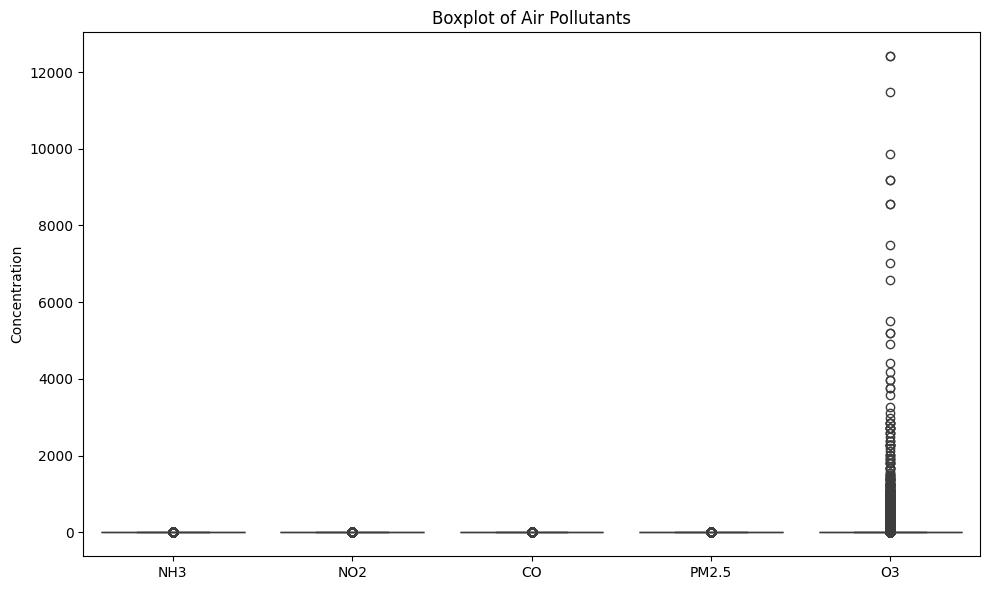

In [ ]:
# Plot 5: Box plots to show spread and outliers
plt.figure(figsize=(10, 6))
sns.boxplot(data[pollutants])
plt.title("Boxplot of Air Pollutants")
plt.ylabel("Concentration")
plt.tight_layout()
plt.show()

- **NH3, NO2, CO, and PM2.5** have relatively compact interquartile ranges (IQRs), indicating consistent measurements with a few moderate outliers.
- **O3** exhibits extreme outliers, extending far beyond 12,000 units. These outliers dominate the y-axis scale and suppress the visibility of variability in the other pollutants.


### PM2.5 – Daily and Weekly Trends

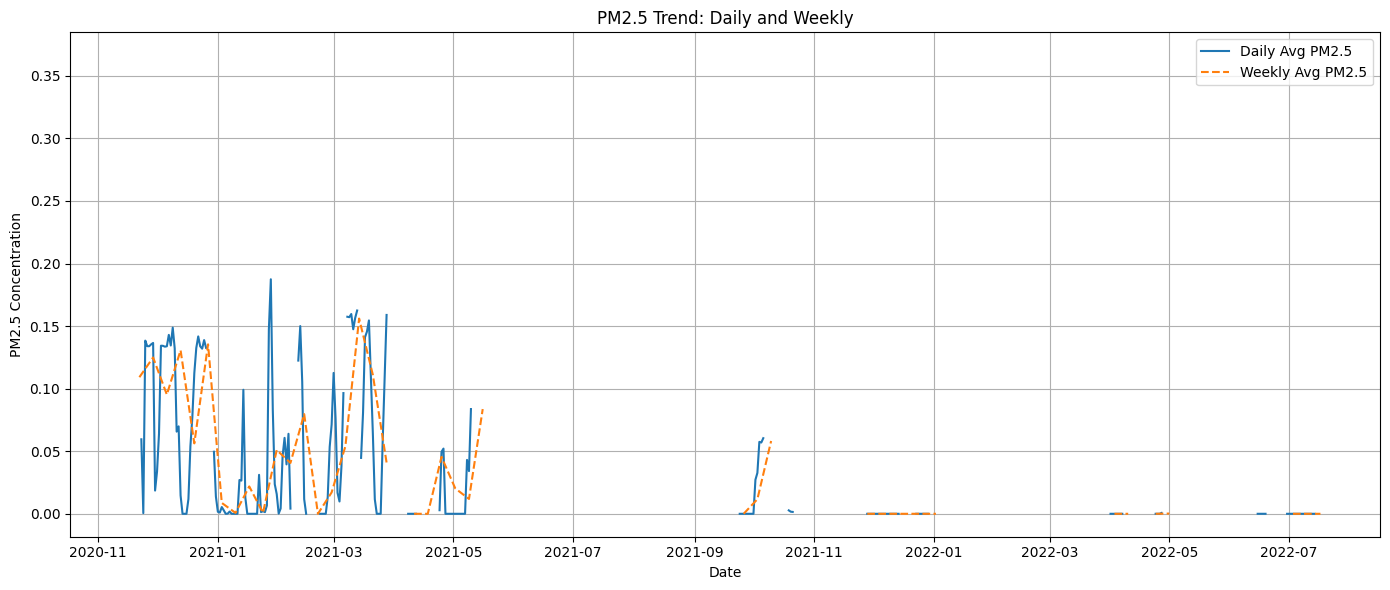

In [ ]:
if 'Date' in data.columns:
    data['Date'] = pd.to_datetime(data['Date'], errors='coerce')
    data = data.set_index('Date')  # Set Date as index
elif data.index.name != 'Date':
    raise ValueError("Date column is missing or not set as index.")

# Drop any rows where Date conversion failed
data = data[~data.index.isna()]

# === 1. PM2.5 Daily and Weekly Trends ===
df_daily = data['PM2.5'].resample('D').mean()
df_weekly = data['PM2.5'].resample('W').mean()

plt.figure(figsize=(14, 6))
plt.plot(df_daily, label='Daily Avg PM2.5')
plt.plot(df_weekly, label='Weekly Avg PM2.5', linestyle='--')
plt.title("PM2.5 Trend: Daily and Weekly")
plt.ylabel("PM2.5 Concentration")
plt.xlabel("Date")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

- The daily trend line shows sharp fluctuations, indicating significant short-term variability likely due to changes in traffic, weather, or human activity.
- The weekly trend smooths these fluctuations, making it easier to observe long-term patterns or seasonal trends.
- There are visible **gaps** in the data, suggesting periods with no or missing readings.
- PM2.5 levels are generally low across the timeline, with occasional peaks indicating transient pollution events.



### Sample Count per Hour

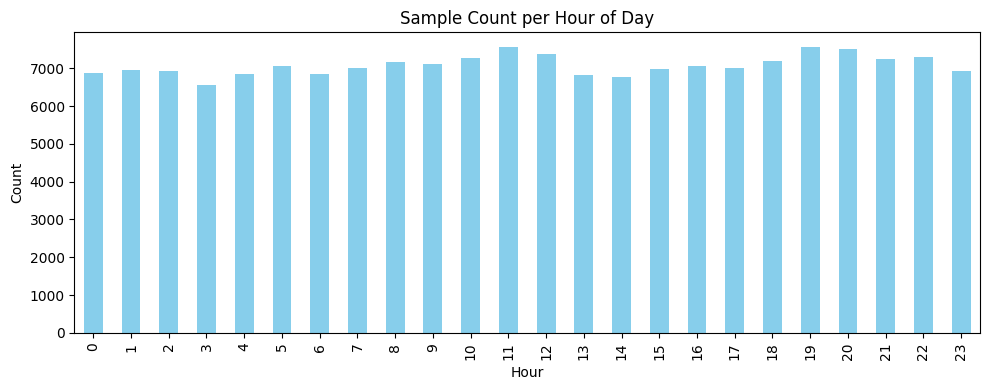

In [ ]:
# --- Sample count by hour ---
data['Hour'] = data.index.hour
plt.figure(figsize=(10, 4))
data['Hour'].value_counts().sort_index().plot(kind='bar', color='skyblue')
plt.title('Sample Count per Hour of Day')
plt.xlabel('Hour')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

### Seasonal Decomposition of PM2.5

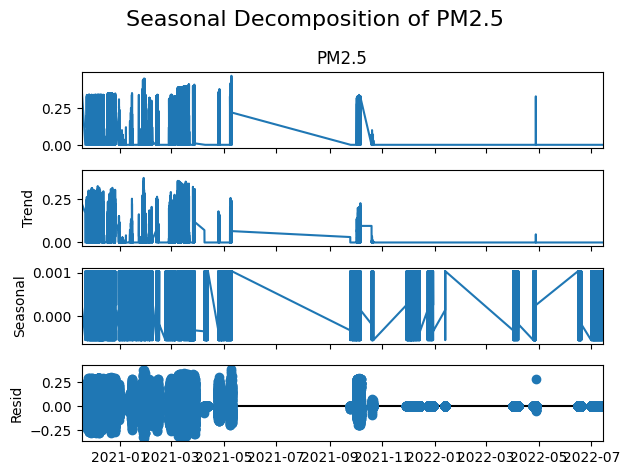

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose
result = seasonal_decompose(data['PM2.5'], model='additive', period=7)
result.plot()
plt.suptitle('Seasonal Decomposition of PM2.5', fontsize=16)
plt.tight_layout()
plt.show()

Key observations:
- The **trend** shows distinct decreasing segments, possibly due to prolonged low pollution periods or data gaps.
- The **seasonal component** is inconsistent, likely due to irregular sampling or missing data.
- The **residuals** are relatively small but densely clustered, with a few deviations indicating anomalies or measurement noise.


### Feature Engineering: Dew Point
Dew point is a derived metric that combines temperature and humidity, giving insight into air moisture levels

In [249]:
data['DewPoint'] = data['Temp'] - ((100 - data['Humidity']) / 5)
data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 169932 entries, 2020-11-17 11:20:53.407872 to 2022-07-14 06:40:39.653879
Data columns (total 9 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   NH3       169932 non-null  float64
 1   NO2       169932 non-null  float64
 2   CO        169932 non-null  float64
 3   PM2.5     169932 non-null  float64
 4   Temp      169932 non-null  float64
 5   Pressure  169932 non-null  float64
 6   Humidity  169932 non-null  float64
 7   O3        169932 non-null  float64
 8   DewPoint  169932 non-null  float64
dtypes: float64(9)
memory usage: 13.0 MB


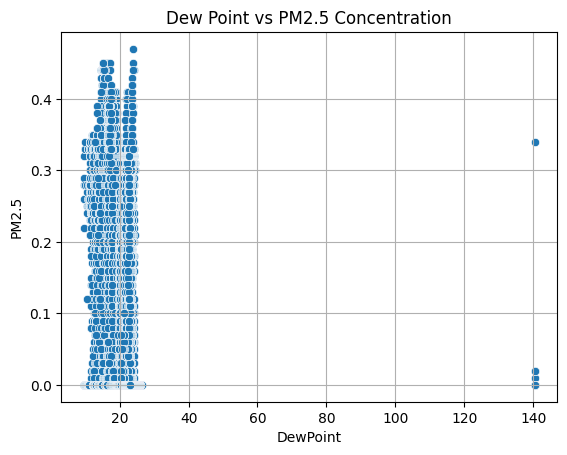

In [250]:
sns.scatterplot(data=data, x='DewPoint', y='PM2.5')
plt.title('Dew Point vs PM2.5 Concentration')
plt.grid(True)
plt.show()

Key observations:
- The majority of the data points are tightly clustered between **dew points of 10°C to 30°C** and **PM2.5 values below 0.3**, suggesting that most samples fall within typical indoor or moderate climate ranges.
- A few extreme outliers (e.g., dew point around 140°C) likely indicate **erroneous sensor readings or faulty data**, as such values are physically implausible in atmospheric conditions.
- No strong linear correlation is visible from the plot; however, there appears to be a **slight positive trend** where higher dew points might be associated with slightly elevated PM2.5 levels—potentially due to moisture retention of fine particles.


<Axes: xlabel='Date'>

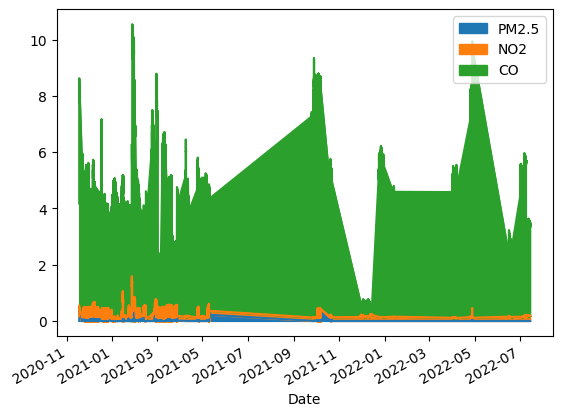

In [251]:
data[['PM2.5', 'NO2', 'CO']].plot.area(stacked=True)

Key observations:
- **CO** (green area) contributes the most consistently and prominently to total pollutant load, often overshadowing the other two variables.
- **NO2** (orange area) appears in smaller amounts with occasional sharp spikes, likely linked to traffic or combustion sources.
- **PM2.5** (blue area) maintains low levels throughout but still contributes regularly to the pollution profile.


# Conversion according to EAQI

In [68]:

# Constants
R = 0.08205  # Ideal gas constant in (L·atm)/(mol·K)
MW = {
    'CO': 28.01,    # Carbon Monoxide in ppm
    'NO2': 46.01,   # Nitrogen Dioxide in ppm
    'NH3': 17.03,   # Ammonia in ppm
    'O3': 48.00     # Ozone in ppb
}

# Conversion functions
def ppm_to_ugm3(ppm, mw, temp_c, pressure_hpa):
    pressure_atm = pressure_hpa / 1013.25
    return (ppm * mw * pressure_atm * 1000) / (R * (temp_c + 273.15))

def ppb_to_ugm3(ppb, mw, temp_c, pressure_hpa):
    pressure_atm = pressure_hpa / 1013.25
    return (ppb * mw * pressure_atm) / (R * (temp_c + 273.15))

# Ensure relevant columns are numeric
for col in ['CO', 'NO2', 'NH3', 'O3', 'Temp', 'Pressure']:
    data[col] = pd.to_numeric(data[col], errors='coerce')

# Apply conversions
data['CO_ugm3'] = ppm_to_ugm3(data['CO'], MW['CO'], data['Temp'], data['Pressure'])
data['NO2_ugm3'] = ppm_to_ugm3(data['NO2'], MW['NO2'], data['Temp'], data['Pressure'])
data['NH3_ugm3'] = ppm_to_ugm3(data['NH3'], MW['NH3'], data['Temp'], data['Pressure'])
data['O3_ugm3'] = ppb_to_ugm3(data['O3'], MW['O3'], data['Temp'], data['Pressure'])


In [38]:
data.describe()

,NH3,NO2,CO,PM2.5,Temp,Pressure,Humidity,O3,CO_ugm3,NO2_ugm3,NH3_ugm3,O3_ugm3
count,169932.000000,169932.000000,169932.000000,169932.000000,169932.000000,169932.000000,169932.000000,169932.000000,169932.000000,169932.000000,169932.000000,169932.000000
mean,0.670122,0.156452,4.347937,0.058650,29.450441,941.255916,46.559770,15.941457,4554.507771,269.495158,426.967612,28.591279
std,0.177409,0.076446,1.626682,0.117004,2.238338,4.379627,16.969909,100.291463,1700.499850,132.372731,112.689439,178.969431
min,0.290000,0.060000,0.290000,0.000000,23.280000,929.750000,13.580000,1.340000,307.296050,103.426084,182.078066,2.388415
25%,0.540000,0.110000,3.620000,0.000000,28.180000,939.380000,33.370000,6.070000,3805.253581,189.887839,345.657361,10.926415
50%,0.650000,0.140000,4.190000,0.000000,29.100000,942.020000,43.500000,9.440000,4398.187409,241.208269,412.133254,16.963296
75%,0.750000,0.170000,4.880000,0.000000,30.620000,943.870000,56.860000,13.320000,5087.290245,289.565740,478.901296,23.927901
max,1.630000,1.420000,9.920000,0.470000,140.460000,1202.850000,100.000000,12413.290000,10429.662058,2478.456408,1041.321853,22150.320849


In [69]:
# Check for missing values
missing_counts = data.isnull().sum()

# Filter only columns that have missing values
missing_counts = missing_counts[missing_counts > 0]

# Show result
print("Columns with missing values:")
print(missing_counts)

Columns with missing values:
NH3            3
CO             3
PM2.5          3
Temp        3529
Pressure    3528
Humidity    3534
O3             3
Date           3
CO_ugm3     3529
NO2_ugm3    3529
NH3_ugm3    3529
O3_ugm3     3529
dtype: int64


In [70]:
# --- Define EAQI breakpoints for each pollutant (in µg/m³) ---
eaqi_breakpoints = {
    'PM2.5': [
        (0.0, 50.4, 0, 50),
        (50.5, 60.4, 51, 100),
        (60.5, 75.4, 101, 150),
        (75.5, 150.4, 151, 200),
        (150.5, 250.4, 201, 300),
        (250.5, 500.4, 301, 500)
    ],
    'CO_ugm3': [  # Converted from mg/m³ to µg/m³
        (0.0, 5400.0, 0, 50),
        (5401.0, 10400.0, 51, 100),
        (10401.0, 14400.0, 101, 150),
        (14401.0, 17900.0, 151, 200),
        (17901.0, 35400.0, 201, 300),
        (35401.0, 58400.0, 301, 500)
    ],
    'NO2_ugm3': [
        (0.0, 100.0, 0, 50),
        (101.0, 400.0, 51, 100),
        (401.0, 677.0, 101, 150),
        (678.0, 1221.0, 151, 200),
        (1222.0, 2349.0, 201, 300),
        (2350.0, 3853.0, 301, 500)
    ],
    'O3_ugm3': [
        (0.0, 100.0, 0, 50),
        (101.0, 400.0, 51, 100),
        (401.0, 677.0, 101, 150),
        (678.0, 1221.0, 151, 200),
        (1222.0, 2349.0, 201, 300),
        (2350.0, 3853.0, 301, 500)
    ]
}

# --- Function to calculate sub-index for a given pollutant ---
def calculate_eaqi_sub_index(value, breakpoints):
    for BPLo, BPHi, ILo, IHi in breakpoints:
        if BPLo <= value <= BPHi:
            return round(((IHi - ILo) / (BPHi - BPLo)) * (value - BPLo) + ILo)
    return None

# --- Calculate EAQI sub-indices ---
data['EAQI_PM25'] = data['PM2.5'].apply(lambda x: calculate_eaqi_sub_index(x, eaqi_breakpoints['PM2.5']))
data['EAQI_CO'] = data['CO_ugm3'].apply(lambda x: calculate_eaqi_sub_index(x, eaqi_breakpoints['CO_ugm3']))
data['EAQI_NO2'] = data['NO2_ugm3'].apply(lambda x: calculate_eaqi_sub_index(x, eaqi_breakpoints['NO2_ugm3']))
data['EAQI_O3'] = data['O3_ugm3'].apply(lambda x: calculate_eaqi_sub_index(x, eaqi_breakpoints['O3_ugm3']))

# --- Final EAQI is the max sub-index across pollutants ---
data['EAQI_Overall'] = data[['EAQI_PM25', 'EAQI_CO', 'EAQI_NO2', 'EAQI_O3']].max(axis=1)

# --- Classify into EAQI categories ---
def classify_eaqi(index_value):
    if pd.isna(index_value):
        return None
    elif index_value <= 50:
        return "Good"
    elif index_value <= 100:
        return "Moderate"
    elif index_value <= 150:
        return "Unhealthy for sensitive groups"
    elif index_value <= 200:
        return "Unhealthy"
    elif index_value <= 300:
        return "Very unhealthy"
    elif index_value <= 500:
        return "Hazardous"
    else:
        return "Out of Range"

data['EAQI_Category'] = data['EAQI_Overall'].apply(classify_eaqi)


In [41]:
data.head

<bound method NDFrame.head of                              NH3   NO2    CO  PM2.5   Temp  Pressure  \
Date                                                                   
2020-11-17 11:20:53.407872  0.60  0.16  4.01   0.00  33.53    948.26   
2020-11-17 11:22:41.214724  0.62  0.15  4.13   0.39  33.50    948.18   
2020-11-17 11:24:28.546567  0.69  0.14  4.45   0.39  33.36    948.15   
2020-11-17 11:26:16.884289  0.70  0.14  4.52   0.38  32.18    948.14   
2020-11-17 11:28:19.820781  0.72  0.14  4.56   0.40  31.77    948.08   
...                          ...   ...   ...    ...    ...       ...   
2022-07-14 06:36:51.411260  0.49  0.18  3.28   0.00  26.19    930.53   
2022-07-14 06:37:48.752963  0.48  0.18  3.28   0.00  26.15    930.53   
2022-07-14 06:38:45.008995  0.47  0.18  3.28   0.00  26.15    930.53   
2022-07-14 06:39:42.306449  0.48  0.18  3.28   0.00  26.16    930.49   
2022-07-14 06:40:39.653879  0.48  0.18  3.28   0.00  26.19    930.50   

                            Humid

In [71]:
# Count each EAQI category
category_counts = data['EAQI_Category'].value_counts().sort_index()

# Format as a table
print("\n📊 EAQI Category Distribution (based on max pollutant per record):\n")
print("| EAQI Category                     | Count     |")
print("|----------------------------------|-----------|")
for category, count in category_counts.items():
    print(f"| {category:<32} | {count:<9} |")


📊 EAQI Category Distribution (based on max pollutant per record):

| EAQI Category                     | Count     |
|----------------------------------|-----------|
| Good                             | 3561      |
| Hazardous                        | 43        |
| Moderate                         | 151223    |
| Unhealthy                        | 2777      |
| Unhealthy for sensitive groups   | 15720     |
| Very unhealthy                   | 141       |


In [72]:
data['EAQI_Category'].value_counts(normalize=True)

EAQI_Category
Moderate                          0.871778
Unhealthy for sensitive groups    0.090623
Good                              0.020529
Unhealthy                         0.016009
Very unhealthy                    0.000813
Hazardous                         0.000248
Name: proportion, dtype: float64

In [44]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
data['EAQI_Label'] = le.fit_transform(data['EAQI_Category'])


In [73]:
# Check for missing values
missing_counts = data.isnull().sum()

# Filter only columns that have missing values
missing_counts = missing_counts[missing_counts > 0]

# Show result
print("Columns with missing values:")
print(missing_counts)

Columns with missing values:
NH3                 3
CO                  3
PM2.5               3
Temp             3529
Pressure         3528
Humidity         3534
O3                  3
Date                3
CO_ugm3          3529
NO2_ugm3         3529
NH3_ugm3         3529
O3_ugm3          3529
EAQI_PM25           3
EAQI_CO          3540
EAQI_NO2         3581
EAQI_O3          3615
EAQI_Overall        3
EAQI_Category       3
dtype: int64


In [46]:
data = data.dropna()


In [47]:
# 1. Import libraries
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier, NearestCentroid
from sklearn.neural_network import MLPClassifier

# External ML libraries
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# 2. Prepare features and target
features = ['PM2.5', 'CO_ugm3', 'NO2_ugm3', 'NH3_ugm3', 'O3_ugm3', 'Temp', 'Humidity', 'Pressure']
X = data[features]
y = data['EAQI_Label']

# 3. Encode target
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# 4. Train-test split (stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, stratify=y_encoded, random_state=42
)

# 5. Scale features for models that require it
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 6. Define models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight='balanced'),
    "Ridge Classifier": RidgeClassifier(class_weight='balanced'),
    "Linear SVM": LinearSVC(class_weight='balanced', max_iter=10000),
    "Random Forest": RandomForestClassifier(class_weight='balanced', random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(eval_metric='mlogloss', random_state=42),
    "LightGBM": LGBMClassifier(class_weight='balanced', random_state=42),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=42),
    "KNN": KNeighborsClassifier(),
    "Nearest Centroid": NearestCentroid(),
    "MLP Classifier": MLPClassifier(random_state=42, max_iter=300)
}

# 7. Train & evaluate models
results = {}

for name, model in models.items():
    # Use scaled data for sensitive models
    if name in ['Logistic Regression', 'Linear SVM', 'KNN', 'Nearest Centroid', 'MLP Classifier']:
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

    report = classification_report(y_test, y_pred, target_names=le.classes_, output_dict=True)
    results[name] = {
        "Accuracy": round(report["accuracy"], 3),
        "Macro F1": round(report["macro avg"]["f1-score"], 3),
        "Weighted F1": round(report["weighted avg"]["f1-score"], 3)
    }

# 8. Show results
results_df = pd.DataFrame(results).T.sort_values(by="Weighted F1", ascending=False)
print(results_df)


KeyboardInterrupt: 

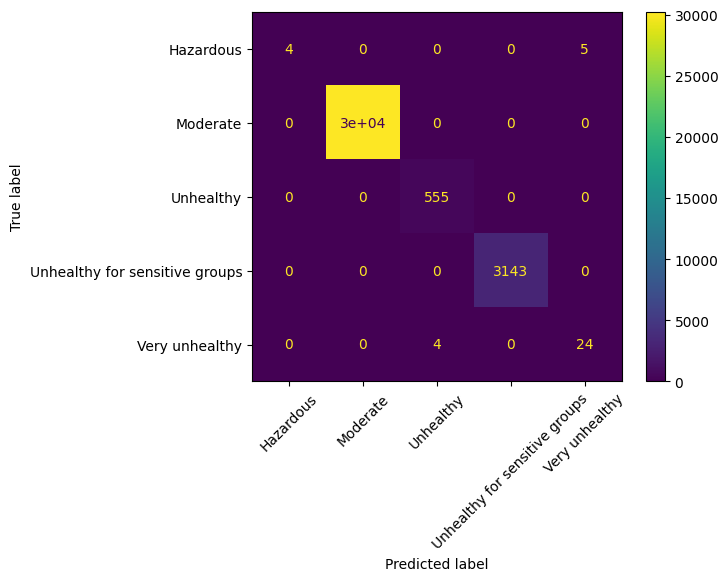

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

best_model = RandomForestClassifier().fit(X_train, y_train)
y_pred = best_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
disp.plot(xticks_rotation=45)


In [ ]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(RandomForestClassifier(), X, y_encoded, cv=5, scoring='f1_weighted')
print("5-Fold CV Weighted F1:", round(cv_scores.mean(), 3))


5-Fold CV Weighted F1: 0.989


In [ ]:
# 1. Import libraries
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier, NearestCentroid
from sklearn.neural_network import MLPClassifier

# External ML libraries
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from imblearn.over_sampling import SMOTE

# 2. Prepare features and target
features = ['PM2.5', 'CO_ugm3', 'NO2_ugm3', 'NH3_ugm3', 'O3_ugm3', 'Temp', 'Humidity', 'Pressure']
X = data[features]
y = data['EAQI_Category']

# 3. Encode target
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# 4. Train-test split (stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, stratify=y_encoded, random_state=42
)

# 5. Scale features
scaler = StandardScaler()
X_test_scaled = scaler.fit_transform(X_test)  # Test scaled once here

# 6. Apply SMOTE on unscaled X_train
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

# Scale only after SMOTE (for sensitive models)
X_train_res_scaled = scaler.fit_transform(X_train_res)

# 7. Define models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight='balanced'),
    "Ridge Classifier": RidgeClassifier(class_weight='balanced'),
    "Linear SVM": LinearSVC(class_weight='balanced', max_iter=10000),
    "Random Forest": RandomForestClassifier(class_weight='balanced', random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(eval_metric='mlogloss', random_state=42),
    "LightGBM": LGBMClassifier(class_weight='balanced', random_state=42),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=42),
    "KNN": KNeighborsClassifier(),
    "Nearest Centroid": NearestCentroid(),
    "MLP Classifier": MLPClassifier(random_state=42, max_iter=300)
}

# 8. Train & evaluate models
results = {}

for name, model in models.items():
    if name in ['Logistic Regression', 'Linear SVM', 'KNN', 'Nearest Centroid', 'MLP Classifier']:
        model.fit(X_train_res_scaled, y_train_res)
        y_pred = model.predict(X_test_scaled)
    else:
        model.fit(X_train_res, y_train_res)
        y_pred = model.predict(X_test)

    report = classification_report(y_test, y_pred, target_names=le.classes_, output_dict=True)
    results[name] = {
        "Accuracy": round(report["accuracy"], 3),
        "Macro F1": round(report["macro avg"]["f1-score"], 3),
        "Weighted F1": round(report["weighted avg"]["f1-score"], 3)
    }

# 9. Show results
results_df = pd.DataFrame(results).T.sort_values(by="Weighted F1", ascending=False)
print(results_df)


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004165 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2040
[LightGBM] [Info] Number of data points in the train set: 604430, number of used features: 8
[LightGBM] [Info] Start training from score -1.609438
[LightGBM] [Info] Start training from score -1.609438
[LightGBM] [Info] Start training from score -1.609438
[LightGBM] [Info] Start training from score -1.609438
[LightGBM] [Info] Start training from score -1.609438
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
                     Accuracy  Macro F1  Weighted F1
Random Forest           1.000     0.977        1.000
Gradient Boosting       1.000     0.981        1.000
XGBoost                 0.998     0.948        0.998
CatBoost       

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004837 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2040
[LightGBM] [Info] Number of data points in the train set: 725832, number of used features: 8
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004110 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Tota

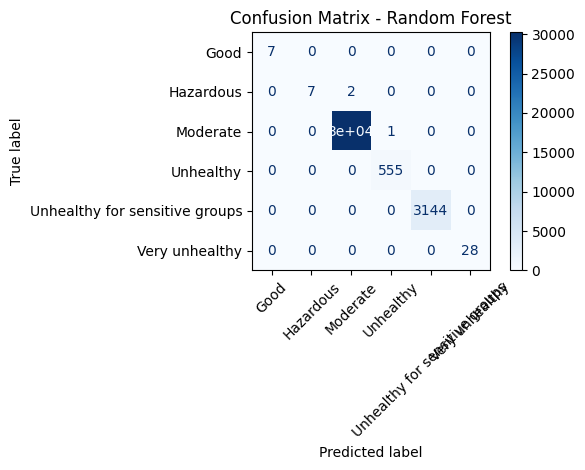

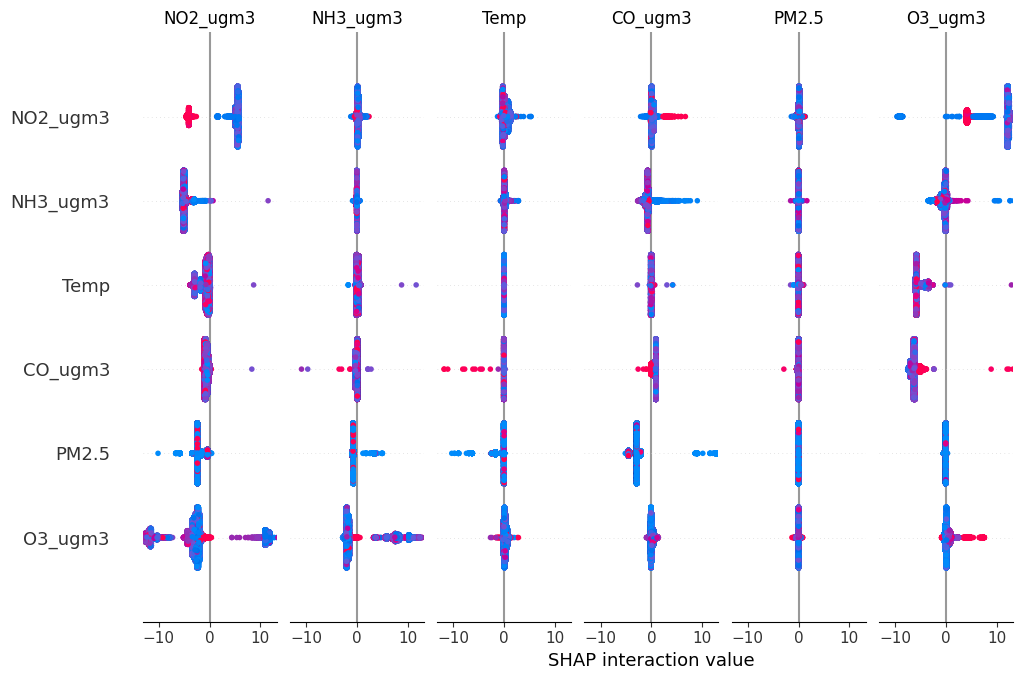

In [263]:
# IAQ Prediction: Full Master's-Level Pipeline

# 1. Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.ensemble import VotingClassifier, RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression, RidgeClassifier, LassoCV, ElasticNetCV
from sklearn.neighbors import KNeighborsClassifier, NearestCentroid
from sklearn.neural_network import MLPClassifier
from sklearn.svm import LinearSVC, SVR
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from imblearn.over_sampling import SMOTE
import shap
import joblib

# 2. Load Data

features = ['PM2.5', 'CO_ugm3', 'NO2_ugm3', 'NH3_ugm3', 'O3_ugm3', 'Temp', 'Humidity', 'Pressure']
X = data[features]
y = data['EAQI_Category']

# 3. Encode Target
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# 4. Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, stratify=y_encoded, random_state=42)

# 5. SMOTE
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

# 6. Scaling
scaler = StandardScaler()
X_train_res_scaled = scaler.fit_transform(X_train_res)
X_test_scaled = scaler.transform(X_test)

# 7. Define Models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight='balanced'),
    "Ridge Classifier": RidgeClassifier(class_weight='balanced'),
    "Linear SVM": LinearSVC(class_weight='balanced', max_iter=10000),
    "Random Forest": RandomForestClassifier(class_weight='balanced', random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(eval_metric='mlogloss', random_state=42),
    "LightGBM": LGBMClassifier(class_weight='balanced', random_state=42),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=42),
    "KNN": KNeighborsClassifier(),
    "Nearest Centroid": NearestCentroid(),
    "MLP Classifier": MLPClassifier(random_state=42, max_iter=300)
}

# 8. Voting Classifier
voting_clf = VotingClassifier(estimators=[
    ('xgb', models['XGBoost']),
    ('lgbm', models['LightGBM']),
    ('cat', models['CatBoost']),
    ('rf', models['Random Forest'])
], voting='soft')
models['Voting Ensemble'] = voting_clf

# 9. Train and Evaluate
results = {}
for name, model in models.items():
    use_scaled = name in ['Logistic Regression', 'Linear SVM', 'KNN', 'Nearest Centroid', 'MLP Classifier']
    model.fit(X_train_res_scaled if use_scaled else X_train_res, y_train_res)
    y_pred = model.predict(X_test_scaled if use_scaled else X_test)
    report = classification_report(y_test, y_pred, target_names=le.classes_, output_dict=True)
    results[name] = {
        "Accuracy": round(report["accuracy"], 3),
        "Macro F1": round(report["macro avg"]["f1-score"], 3),
        "Weighted F1": round(report["weighted avg"]["f1-score"], 3)
    }

# 10. Results Summary
results_df = pd.DataFrame(results).T.sort_values(by="Weighted F1", ascending=False)
print("\nModel Performance Summary:")
print(results_df)

# 11. Confusion Matrix for Top Model
top_model_name = results_df.index[0]
y_pred_top = models[top_model_name].predict(X_test_scaled if top_model_name in ['Logistic Regression', 'Linear SVM', 'KNN', 'Nearest Centroid', 'MLP Classifier'] else X_test)
cm = confusion_matrix(y_test, y_pred_top)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_).plot(cmap='Blues', xticks_rotation=45)
plt.title(f"Confusion Matrix - {top_model_name}")
plt.tight_layout()
plt.show()

# 12. SHAP Explainability
explainer = shap.TreeExplainer(models['LightGBM'])
shap_values = explainer.shap_values(X_test)
shap.summary_plot(shap_values, X_test, feature_names=features)

# 13. Save Model
joblib.dump(models[top_model_name], 'best_model.pkl')
joblib.dump(scaler, 'feature_scaler.pkl')
joblib.dump(le, 'label_encoder.pkl')

# 14. Optional: Regression Model for AQI Index
if 'EAQI_Index' in data.columns:
    reg = ElasticNetCV(cv=5).fit(X_train_res, data.loc[y_train_res.index, 'EAQI_Index'])
    print("ElasticNet regression model score:", reg.score(X_test, data.loc[y_test.index, 'EAQI_Index']))


Before Split:
 EAQI_Category
Moderate                          151216
Unhealthy for sensitive groups     15720
Unhealthy                           2777
Very unhealthy                       141
Hazardous                             43
Good                                  35
Name: count, dtype: int64


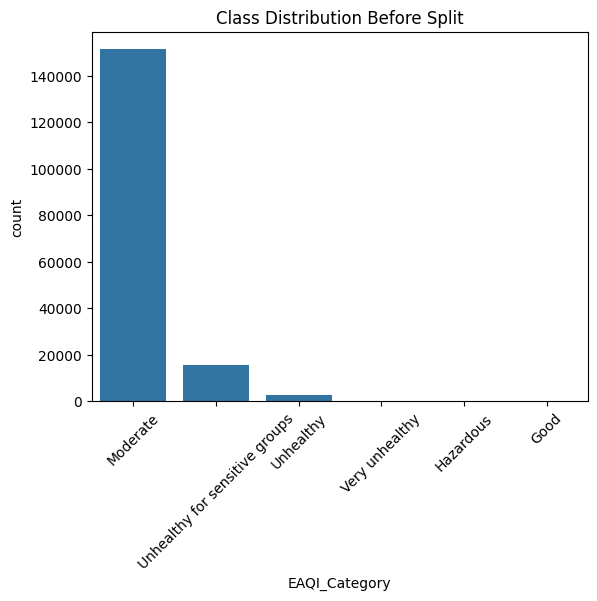

In [264]:
import matplotlib.pyplot as plt
import seaborn as sns

# Original class distribution
class_counts = data['EAQI_Category'].value_counts()
print("Before Split:\n", class_counts)

# Plot
sns.countplot(x='EAQI_Category', data=data, order=class_counts.index)
plt.title("Class Distribution Before Split")
plt.xticks(rotation=45)
plt.show()


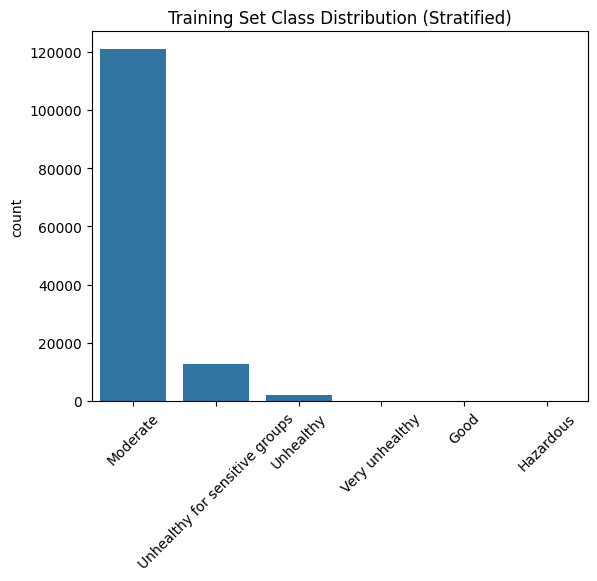

In [265]:
from sklearn.model_selection import train_test_split

# Encode target
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y_encoded = le.fit_transform(data['EAQI_Category'])

X = data[features]
y = y_encoded

# Stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, stratify=y, test_size=0.2, random_state=42
)

# Convert back to label for visualization
y_train_labels = le.inverse_transform(y_train)
sns.countplot(x=y_train_labels)
plt.title("Training Set Class Distribution (Stratified)")
plt.xticks(rotation=45)
plt.show()


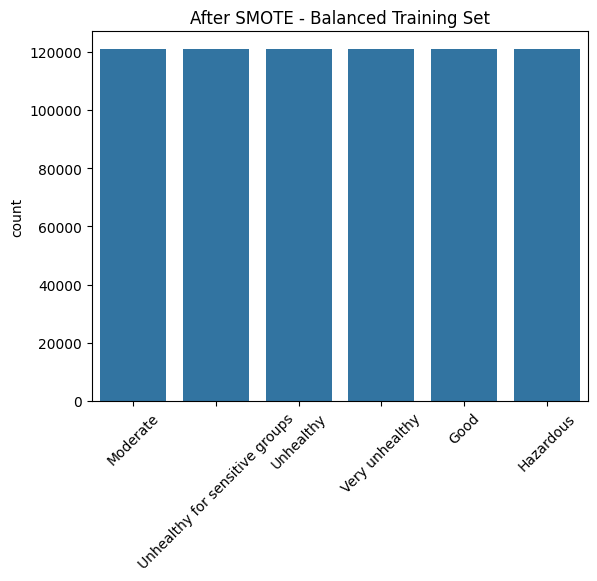

In [267]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_train, y_train)

# Visualize after SMOTE
resampled_labels = le.inverse_transform(y_resampled)
sns.countplot(x=resampled_labels)
plt.title("After SMOTE - Balanced Training Set")
plt.xticks(rotation=45)
plt.show()


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003479 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2040
[LightGBM] [Info] Number of data points in the train set: 580662, number of used features: 8
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003806 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memo

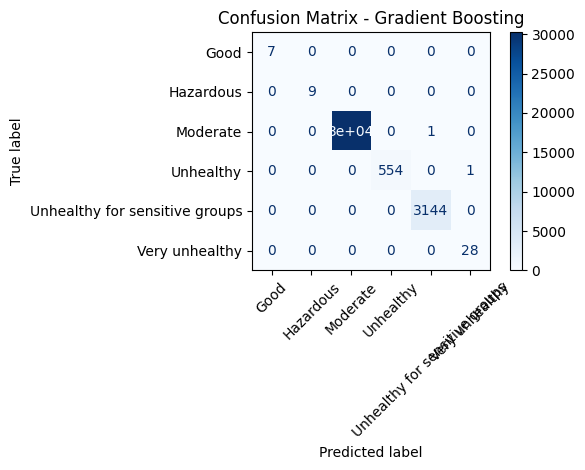

['label_encoder.pkl']

In [269]:
# 1. Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.neighbors import KNeighborsClassifier, NearestCentroid
from sklearn.neural_network import MLPClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
import joblib

# 2. Load and Prepare Data

features = ['PM2.5', 'CO_ugm3', 'NO2_ugm3', 'NH3_ugm3', 'O3_ugm3', 'Temp', 'Humidity', 'Pressure']
X = data[features]
y = data['EAQI_Category']

# 3. Encode Target
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# 4. Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, stratify=y_encoded, random_state=42
)

# 5. Define Models inside SMOTE Pipelines
models = {
    "Logistic Regression": ImbPipeline([
        ('smote', SMOTE(random_state=42)),
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(max_iter=1000, class_weight='balanced'))
    ]),
    "Ridge Classifier": ImbPipeline([
        ('smote', SMOTE(random_state=42)),
        ('scaler', StandardScaler()),
        ('clf', RidgeClassifier(class_weight='balanced'))
    ]),
    "Linear SVM": ImbPipeline([
        ('smote', SMOTE(random_state=42)),
        ('scaler', StandardScaler()),
        ('clf', LinearSVC(max_iter=10000, class_weight='balanced'))
    ]),
    "Random Forest": ImbPipeline([
        ('smote', SMOTE(random_state=42)),
        ('clf', RandomForestClassifier(class_weight='balanced', random_state=42))
    ]),
    "Gradient Boosting": ImbPipeline([
        ('smote', SMOTE(random_state=42)),
        ('clf', GradientBoostingClassifier(random_state=42))
    ]),
    "XGBoost": ImbPipeline([
        ('smote', SMOTE(random_state=42)),
        ('clf', XGBClassifier(eval_metric='mlogloss', random_state=42))
    ]),
    "LightGBM": ImbPipeline([
        ('smote', SMOTE(random_state=42)),
        ('clf', LGBMClassifier(class_weight='balanced', random_state=42))
    ]),
    "CatBoost": ImbPipeline([
        ('smote', SMOTE(random_state=42)),
        ('clf', CatBoostClassifier(verbose=0, random_state=42))
    ]),
    "KNN": ImbPipeline([
        ('smote', SMOTE(random_state=42)),
        ('scaler', StandardScaler()),
        ('clf', KNeighborsClassifier())
    ]),
    "Nearest Centroid": ImbPipeline([
        ('smote', SMOTE(random_state=42)),
        ('scaler', StandardScaler()),
        ('clf', NearestCentroid())
    ]),
    "MLP Classifier": ImbPipeline([
        ('smote', SMOTE(random_state=42)),
        ('scaler', StandardScaler()),
        ('clf', MLPClassifier(random_state=42, max_iter=300))
    ]),
    "Naive Bayes": ImbPipeline([
        ('smote', SMOTE(random_state=42)),
        ('scaler', StandardScaler()),
        ('clf', GaussianNB())
    ])
}

# 6. Evaluate Models Using Cross-Validation
results = {}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, pipe in models.items():
    f1_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='f1_macro')
    results[name] = {
        "CV Macro F1 (mean)": round(np.mean(f1_scores), 4),
        "CV Macro F1 (std)": round(np.std(f1_scores), 4)
    }

# 7. Display Evaluation Results
results_df = pd.DataFrame(results).T.sort_values(by="CV Macro F1 (mean)", ascending=False)
print("\n📊 Model Performance Summary:")
print(results_df)

# 8. Train Best Model Fully and Evaluate on Test Set
best_model_name = results_df.index[0]
print(f"\n✅ Training best model: {best_model_name}")
best_model = models[best_model_name]
best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)

print(f"\n🧾 Classification Report for {best_model_name}:")
print(classification_report(y_test, y_pred, target_names=le.classes_))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=le.classes_, xticks_rotation=45, cmap='Blues')
plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()

# 9. Save Model
joblib.dump(best_model, "best_model_pipeline.pkl")
joblib.dump(le, "label_encoder.pkl")


In [74]:
# iaq_model_training.py

import pandas as pd
import numpy as np
import joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.metrics import classification_report


features = ['PM2.5', 'CO_ugm3', 'NO2_ugm3', 'NH3_ugm3', 'O3_ugm3', 'Temp', 'Humidity', 'Pressure']
X = data[features]
y = data['EAQI_Category']

# 2. Encode target
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# 3. Split
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, stratify=y_encoded, random_state=42)

# 4. Define pipeline with SMOTE and scaler + classifier
pipeline = ImbPipeline(steps=[
    ('smote', SMOTE(random_state=42)),
    ('scaler', StandardScaler()),
    ('clf', GradientBoostingClassifier(random_state=42))
])

# 5. Cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(pipeline, X_train, y_train, scoring='f1_macro', cv=cv)
print(f"CV Macro F1: {np.mean(scores):.4f} ± {np.std(scores):.4f}")

# 6. Final training
pipeline.fit(X_train, y_train)

# 7. Evaluate
y_pred = pipeline.predict(X_test)
print(classification_report(y_test, y_pred, target_names=le.classes_))

# 8. Save pipeline and label encoder
joblib.dump(pipeline, 'best_model_pipeline03.pkl')
joblib.dump(le, 'label_encoder03.pkl')


/Users/anugrahaantoo/Desktop/Final Project /Indoor_Air_Quality_Prediction/venv/lib/python3.13/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=5.
  warnings.warn(


ValueError: 
All the 5 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
5 fits failed with the following error:
Traceback (most recent call last):
  File "/Users/anugrahaantoo/Desktop/Final Project /Indoor_Air_Quality_Prediction/venv/lib/python3.13/site-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/anugrahaantoo/Desktop/Final Project /Indoor_Air_Quality_Prediction/venv/lib/python3.13/site-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/Users/anugrahaantoo/Desktop/Final Project /Indoor_Air_Quality_Prediction/venv/lib/python3.13/site-packages/imblearn/pipeline.py", line 518, in fit
  

In [51]:
from collections import Counter
print(Counter(pipeline.predict(X_test)))


Counter({np.int64(1): 30222, np.int64(3): 3143, np.int64(2): 554, np.int64(4): 30, np.int64(0): 8})


In [54]:
print("Original class distribution:")
print(y.value_counts())
print("\nTest set distribution:")
print(pd.Series(y_test).value_counts())


Original class distribution:
EAQI_Category
Moderate                          151108
Unhealthy for sensitive groups     15715
Unhealthy                           2777
Very unhealthy                       141
Hazardous                             43
Name: count, dtype: int64

Test set distribution:
1    30222
3     3143
2      555
4       28
0        9
Name: count, dtype: int64


In [50]:
print("Prediction Distribution:")
print(pd.Series(y_pred).value_counts())


Prediction Distribution:
1    30222
3     3143
2      554
4       30
0        8
Name: count, dtype: int64


In [53]:
import pandas as pd
import numpy as np
import joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report
from sklearn.ensemble import GradientBoostingClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# Load data

data.dropna(subset=['EAQI_Category'], inplace=True)
features = ['PM2.5', 'CO_ugm3', 'NO2_ugm3', 'NH3_ugm3', 'O3_ugm3', 'Temp', 'Humidity', 'Pressure']
data.dropna(subset=features, inplace=True)

X = data[features]
y = data['EAQI_Category']

# Encode target
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Split
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, stratify=y_encoded, random_state=42)

# Updated: Apply scaler before SMOTE
pipeline = ImbPipeline(steps=[
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42)),
    ('clf', GradientBoostingClassifier(random_state=42))
])

# Cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(pipeline, X_train, y_train, scoring='f1_macro', cv=cv)
print(f"CV Macro F1: {np.mean(scores):.4f} ± {np.std(scores):.4f}")

# Final training
pipeline.fit(X_train, y_train)

# Evaluate
y_pred = pipeline.predict(X_test)
print(classification_report(y_test, y_pred, target_names=le.classes_))

# Save
joblib.dump(pipeline, 'best_model_pipeline.pkl')
joblib.dump(le, 'label_encoder.pkl')


/var/folders/47/hprbxv8x771c4vlvp4hrd4n80000gn/T/ipykernel_51918/4011501465.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data.dropna(subset=['EAQI_Category'], inplace=True)
/var/folders/47/hprbxv8x771c4vlvp4hrd4n80000gn/T/ipykernel_51918/4011501465.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data.dropna(subset=features, inplace=True)


CV Macro F1: 0.9941 ± 0.0119
                                precision    recall  f1-score   support

                     Hazardous       1.00      0.89      0.94         9
                      Moderate       1.00      1.00      1.00     30222
                     Unhealthy       1.00      1.00      1.00       555
Unhealthy for sensitive groups       1.00      1.00      1.00      3143
                Very unhealthy       0.93      1.00      0.97        28

                      accuracy                           1.00     33957
                     macro avg       0.99      0.98      0.98     33957
                  weighted avg       1.00      1.00      1.00     33957



['label_encoder.pkl']

In [55]:
print(list(le.classes_))  # Should show ['Hazardous', 'Moderate', ...]


['Hazardous', 'Moderate', 'Unhealthy', 'Unhealthy for sensitive groups', 'Very unhealthy']


In [56]:
import pandas as pd
import numpy as np
import joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.metrics import classification_report
from collections import Counter



# Optional: drop or impute missing values
data = data.dropna(subset=['PM2.5', 'CO_ugm3', 'NO2_ugm3', 'NH3_ugm3', 'O3_ugm3', 'Temp', 'Humidity', 'Pressure', 'EAQI_Category'])

# 2. Downsample 'Moderate' class
majority_class = "Moderate"
majority_df = data[data["EAQI_Category"] == majority_class].sample(n=10000, random_state=42)
minority_df = data[data["EAQI_Category"] != majority_class]
balanced_data = pd.concat([majority_df, minority_df], ignore_index=True)

# 3. Prepare features and target
features = ['PM2.5', 'CO_ugm3', 'NO2_ugm3', 'NH3_ugm3', 'O3_ugm3', 'Temp', 'Humidity', 'Pressure']
X = balanced_data[features]
y = balanced_data['EAQI_Category']

# 4. Encode labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# 5. Split
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, stratify=y_encoded, random_state=42)

# 6. Pipeline: SMOTE + Scaling + Classifier
pipeline = ImbPipeline(steps=[
    ('smote', SMOTE(random_state=42)),
    ('scaler', StandardScaler()),
    ('clf', GradientBoostingClassifier(random_state=42))
])

# 7. Cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(pipeline, X_train, y_train, scoring='f1_macro', cv=cv)
print(f"CV Macro F1: {np.mean(scores):.4f} ± {np.std(scores):.4f}")

# 8. Final training
pipeline.fit(X_train, y_train)

# 9. Evaluation
y_pred = pipeline.predict(X_test)
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=le.classes_))

# 10. Save model and encoder
joblib.dump(pipeline, "best_model_pipeline1.pkl")
joblib.dump(le, "label_encoder1.pkl")


CV Macro F1: 0.9990 ± 0.0018

Classification Report:

                                precision    recall  f1-score   support

                     Hazardous       1.00      0.89      0.94         9
                      Moderate       1.00      1.00      1.00      2000
                     Unhealthy       1.00      1.00      1.00       556
Unhealthy for sensitive groups       1.00      1.00      1.00      3143
                Very unhealthy       0.97      1.00      0.98        28

                      accuracy                           1.00      5736
                     macro avg       0.99      0.98      0.98      5736
                  weighted avg       1.00      1.00      1.00      5736



['label_encoder1.pkl']

In [57]:
print(pd.Series(y_test).value_counts())


3    3143
1    2000
2     556
4      28
0       9
Name: count, dtype: int64


In [58]:
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.ensemble import GradientBoostingClassifier

# Compute class weights
sample_weights = compute_sample_weight(class_weight='balanced', y=y_train)

# Train without SMOTE
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

clf = GradientBoostingClassifier(random_state=42, max_depth=3)
clf.fit(X_train_scaled, y_train, sample_weight=sample_weights)

# Evaluate
y_pred = clf.predict(X_test_scaled)
print(classification_report(y_test, y_pred, target_names=le.classes_))


                                precision    recall  f1-score   support

                     Hazardous       1.00      0.89      0.94         9
                      Moderate       1.00      1.00      1.00      2000
                     Unhealthy       1.00      1.00      1.00       556
Unhealthy for sensitive groups       1.00      1.00      1.00      3143
                Very unhealthy       0.96      0.96      0.96        28

                      accuracy                           1.00      5736
                     macro avg       0.99      0.97      0.98      5736
                  weighted avg       1.00      1.00      1.00      5736



In [59]:
data.describe


<bound method NDFrame.describe of                              NH3   NO2    CO  PM2.5   Temp  Pressure  \
Date                                                                   
2020-11-17 11:20:53.407872  0.60  0.16  4.01   0.00  33.53    948.26   
2020-11-17 11:22:41.214724  0.62  0.15  4.13   0.39  33.50    948.18   
2020-11-17 11:24:28.546567  0.69  0.14  4.45   0.39  33.36    948.15   
2020-11-17 11:26:16.884289  0.70  0.14  4.52   0.38  32.18    948.14   
2020-11-17 11:28:19.820781  0.72  0.14  4.56   0.40  31.77    948.08   
...                          ...   ...   ...    ...    ...       ...   
2022-07-14 06:36:51.411260  0.49  0.18  3.28   0.00  26.19    930.53   
2022-07-14 06:37:48.752963  0.48  0.18  3.28   0.00  26.15    930.53   
2022-07-14 06:38:45.008995  0.47  0.18  3.28   0.00  26.15    930.53   
2022-07-14 06:39:42.306449  0.48  0.18  3.28   0.00  26.16    930.49   
2022-07-14 06:40:39.653879  0.48  0.18  3.28   0.00  26.19    930.50   

                            H


Classification Report:

                                precision    recall  f1-score   support

                     Hazardous       1.00      0.89      0.94         9
                      Moderate       1.00      1.00      1.00     30222
                     Unhealthy       1.00      1.00      1.00       555
Unhealthy for sensitive groups       1.00      1.00      1.00      3143
                Very unhealthy       0.96      0.96      0.96        28

                      accuracy                           1.00     33957
                     macro avg       0.99      0.97      0.98     33957
                  weighted avg       1.00      1.00      1.00     33957



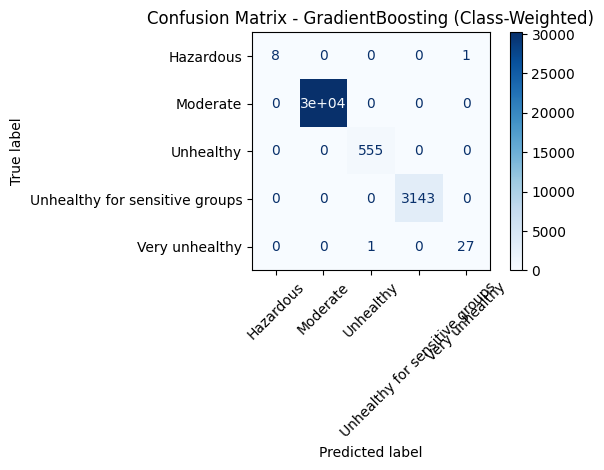

['label_encoder2.pkl']

In [60]:
# iaq_model_training_weighted.py

import pandas as pd
import numpy as np
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.utils.class_weight import compute_sample_weight
import matplotlib.pyplot as plt



# 2. Select features and target
features = ['PM2.5', 'CO_ugm3', 'NO2_ugm3', 'NH3_ugm3', 'O3_ugm3', 'Temp', 'Humidity', 'Pressure']
X = data[features]
y = data['EAQI_Category']

# 3. Encode target labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# 4. Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, stratify=y_encoded, random_state=42
)

# 5. Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 6. Compute class weights
sample_weights = compute_sample_weight(class_weight='balanced', y=y_train)

# 7. Train model with class weights
model = GradientBoostingClassifier(random_state=42, max_depth=4)
model.fit(X_train_scaled, y_train, sample_weight=sample_weights)

# 8. Predict and evaluate
y_pred = model.predict(X_test_scaled)
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=le.classes_))

# 9. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
disp.plot(cmap='Blues', xticks_rotation=45)
plt.title("Confusion Matrix - GradientBoosting (Class-Weighted)")
plt.tight_layout()
plt.show()

# 10. Save model and encoder
joblib.dump(model, "best_model_pipeline2.pkl")
joblib.dump(scaler, "feature_scaler2.pkl")
joblib.dump(le, "label_encoder2.pkl")
